# Reinforcement learning for three virtual asteroid nudges

This notebook **adds** a Gymnasium environment to the v8 continuous 10-parameter estimator. An RL decision determines **where and how to nudge** the asteroid; continuous identification is handled by your existing estimator.

**Default mode:** fast, approximate impulse-based training surrogate. **Validation mode:** your complete MuJoCo spacecraft/CBF simulation (expensive). Both modes reward **information gain only**; neither adds an asteroid keep-in or drift penalty.

**Research caution:** This is a testbed, not evidence that RL outperforms your Sobol/E-optimal planner. Always compare against that baseline on held-out seeds and examine final parameter errors. The Gram matrix and score are heuristic information diagnostics, not calibrated uncertainty.

In [1]:
from pathlib import Path
import sys
import numpy as np

# Handles running from either repository root or its notebooks/ folder.
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "three_nudge_virtual_10param.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "three_nudge_virtual_10param.py").is_file():
    raise FileNotFoundError("Open this notebook from active_inertial_id/notebooks or active_inertial_id")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.three_nudge_virtual_10param import Virtual10Settings, select_virtual_plan
from src.virtual_nudge_rl_env import (VirtualNudgePlacementEnv, RLEnvConfig,
                                      plan_to_normalized_action)
print("Repository:", ROOT)

Repository: /Users/aelkebir/active_inertial_id


## 1. Create environment and check the Gymnasium API

Each `env.step(action)` performs **one complete nudge and observation**. Three RL steps form an episode. Observations consist of estimates and observed state, not ground truth.

In [2]:
from stable_baselines3.common.env_checker import check_env

settings = Virtual10Settings(noise_std=0.0, prior_sigma_normalized=10.0)
rl_settings = RLEnvConfig(backend="surrogate", observation_s=30.0,
                          randomize_surrogate_truth=True)
env = VirtualNudgePlacementEnv(ROOT, settings=settings, rl_config=rl_settings)
check_env(env, warn=True, skip_render_check=True)
obs, info = env.reset(seed=19)
print("Action space:", env.action_space)
print("Observation space:", env.observation_space)
print("Observation features:", obs.shape)
print("Initial estimated mass:", env.identifier.pi[0], "kg")

Action space: Box(-1.0, 1.0, (6,), float32)
Observation space: Box(-1.0, 1.0, (84,), float32)
Observation features: (84,)
Initial estimated mass: 600.0 kg


/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: divide by zero encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: overflow encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: invalid value encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero

## 2. Run three random nudges as a sanity check

In [3]:
obs, _ = env.reset(seed=19)
random_nudge_points = []
for k in range(3):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    print(f"Nudge {k+1}: reward={reward:.3f}, rank={info.get('numerical_rank')}, "
          f"mass={info.get('estimated_pi', np.zeros(10))[0]:.2f} kg, "
          f"impulse={info.get('impulse_Ns')} N·s")
    if 'point_body_m' in info:
        random_nudge_points.append((info['point_body_m'].copy(),
                                    info['push_body'].copy()))
    if info.get('failure_reason'):
        print("Failure:", info['failure_reason'])
        break
print("Estimated parameters:", np.round(env.identifier.pi, 4))

Nudge 1: reward=1.103, rank=10, mass=494.75 kg, impulse=1.7186034440994262 N·s
Nudge 2: reward=0.353, rank=10, mass=494.47 kg, impulse=1.1776872269809247 N·s
Nudge 3: reward=0.945, rank=10, mass=494.46 kg, impulse=1.3509397774934768 N·s
Estimated parameters: [ 4.944638e+02  2.817000e+00 -1.892000e-01  8.519000e-01  4.786170e+01
  4.760730e+01  3.980000e+01 -1.960100e+00  4.072000e-01  1.599600e+00]


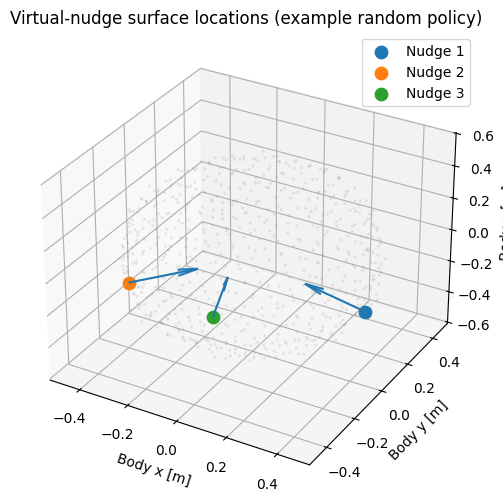

In [4]:
# Visualize nudge locations on the asteroid's convex-hull surface.
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
verts = env.surface.vertices
ax.scatter(verts[:, 0], verts[:, 1], verts[:, 2], s=2, alpha=0.1, color='gray')
for k, (pt, direction) in enumerate(random_nudge_points, start=1):
    ax.scatter(*pt, s=80, label=f'Nudge {k}')
    ax.quiver(*pt, *direction, length=0.25, normalize=True)
ax.set(xlabel='Body x [m]', ylabel='Body y [m]', zlabel='Body z [m]',
       title='Virtual-nudge surface locations (example random policy)')
ax.legend()
plt.show()

## 3. Evaluate the original Sobol/E-optimal planner using the *same* environment

This is the critical benchmark for determining whether learning brings a meaningful benefit.

In [5]:
obs, _ = env.reset(seed=19)
for k in range(3):
    plan, _ = select_virtual_plan(env.surface, env.identifier.last_state,
                                   env.identifier, None, env.cfg, k+1,
                                   np.random.default_rng(100+k))
    action = plan_to_normalized_action(plan, env.surface, env.cfg)
    obs, reward, terminated, truncated, info = env.step(action)
    print(f"Sobol nudge {k+1}: reward={reward:.3f}, rank={info.get('numerical_rank')}, "
          f"mass={info['estimated_pi'][0]:.3f} kg")
    if terminated or truncated:
        break

/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: divide by zero encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: overflow encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: invalid value encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero

Sobol nudge 1: reward=1.118, rank=10, mass=493.769 kg
Sobol nudge 2: reward=0.746, rank=10, mass=494.362 kg
Sobol nudge 3: reward=1.303, rank=10, mass=494.461 kg


## 4. Train a SAC policy (optional)

SAC training can take many episodes. The following cell is disabled until you explicitly change `RUN_TRAINING` to `True`. Training on the surrogate is much faster than running 30-second MuJoCo simulations for every RL action.

In [10]:
from stable_baselines3 import SAC

RUN_TRAINING = True
MODEL_PATH = ROOT / "results" / "rl_virtual_nudges" / "sac_virtual_nudge"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

if RUN_TRAINING:
    train_env = VirtualNudgePlacementEnv(
        ROOT, settings=Virtual10Settings(noise_std=0.0),
        rl_config=RLEnvConfig(backend='surrogate', randomize_surrogate_truth=True))
    model = SAC("MlpPolicy", train_env, verbose=1, seed=19,
                learning_starts=1000, buffer_size=30_000, batch_size=128)
    model.learn(total_timesteps=20_000)
    model.save(str(MODEL_PATH))
    train_env.close()
else:
    print("Training skipped. Set RUN_TRAINING=True when ready.")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: divide by zero encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: overflow encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: invalid value encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 1.75     |
| time/              |          |
|    episodes        | 4        |
|    fps             | 57       |
|    time_elapsed    | 0        |
|    total_timesteps | 12       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 1.86     |
| time/              |          |
|    episodes        | 8        |
|    fps             | 56       |
|    time_elapsed    | 0        |
|    total_timesteps | 24       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 1.95     |
| time/              |          |
|    episodes        | 12       |
|    fps             | 56       |
|    time_elapsed    | 0        |
|    total_timesteps | 36       |
--------------

## 5. Evaluate a trained policy on held-out episodes

Use **different seeds from training**, compare random, Sobol/E-optimal and RL rewards and **ground-truth parameter errors only after each episode**. Debug errors are included in `info` when requested but never in the policy observation/reward.

In [12]:
EVALUATE_TRAINED = True
if EVALUATE_TRAINED:
    model = SAC.load(str(MODEL_PATH), device="cpu")
    eval_env = VirtualNudgePlacementEnv(
        ROOT, settings=Virtual10Settings(noise_std=1e-4),
        rl_config=RLEnvConfig(backend='surrogate', debug_truth=True))
    for seed in (201, 202, 203):
        observation, _ = eval_env.reset(seed=seed)
        done = False
        total_reward = 0.0
        while not done:
            action, _ = model.predict(observation, deterministic=True)
            observation, reward, terminated, truncated, info = eval_env.step(action)
            total_reward += reward
            done = terminated or truncated
        print(seed, "reward", round(total_reward, 3), "errors", info.get('DEV_ONLY_errors'))
    eval_env.close()
else:
    print("Trained-policy evaluation skipped.")

/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: divide by zero encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: overflow encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/three_nudge_virtual_10param.py:348: RuntimeWarning: invalid value encountered in matmul
  unobs = V[:, rank:] @ V[:, rank:].T
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: divide by zero encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: overflow encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:33: RuntimeWarning: invalid value encountered in matmul
  denom=self.A@direction
/Users/aelkebir/active_inertial_id/src/asteroid_surface.py:42: RuntimeWarning: divide by zero

201 reward 7.714 errors {'mass_abs_error_kg': 41.98040201484048, 'com_error_mm': 140.50716062600398, 'inertia_fro_error_kgm2': 67.55083297452552}
202 reward 4.414 errors {'mass_abs_error_kg': 234.85564414540204, 'com_error_mm': 270.24506432211774, 'inertia_fro_error_kgm2': 58.939388422527536}
203 reward 7.227 errors {'mass_abs_error_kg': 38.10002423757527, 'com_error_mm': 67.82728064239414, 'inertia_fro_error_kgm2': 59.859904470267146}


## 6. Verify on MuJoCo (optional, slow)

This executes the real virtual-force simulation, preserves the **existing spacecraft CBF**, and updates the estimator **at every physics timestep**. The policy is *not* guaranteed safe or accurate merely because it succeeds in the training surrogate. Run only after training a model and testing the environment.

In [13]:
RUN_MUJOCO = False
if RUN_MUJOCO:
    model = SAC.load(str(MODEL_PATH), device="cpu")
    mj_env = VirtualNudgePlacementEnv(
        ROOT, settings=Virtual10Settings(noise_std=0.0),
        rl_config=RLEnvConfig(backend='mujoco', debug_truth=True))
    obs, _ = mj_env.reset(seed=101)
    for k in range(3):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = mj_env.step(action)
        print(f"MuJoCo nudge {k+1}, reward={reward:.3f}, "
              f"diagnostic errors={info.get('DEV_ONLY_errors')}, "
              f"CBF interventions={info.get('cbf_interventions_this_nudge')}")
        if terminated or truncated:
            break
    mj_env.close()
else:
    print("MuJoCo evaluation skipped.")

MuJoCo evaluation skipped.


In [9]:
env.close()